# Quantum computing patents: who files, how concentrated, how open

**Input:** the harmonized applicant–family table (`harmonization_output.csv`), one row per applicant per patent family.
**Unit of count:** the DOCDB patent family, so one invention filed in several offices counts once.

All parameters are set in the next cell.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats

DATA_PATH = "harmonization_output.csv"

SECTOR = "COMPANY"     # market analysis is limited to firms
YEAR_MAX = 2022        # last year treated as complete (filings are published ~18 months later)
SPLIT_YEAR = 2015      # incumbent = firm with >= MIN_FAMILIES families before this year
MIN_FAMILIES = 2
EXIT_WINDOW = 3        # a firm counts as "gone" only if we can observe 3 later years without filings
PLOT_FROM = 2005       # earlier years have too few filings to read rates

# Periods used to follow concentration over time
PERIOD_BINS = [-np.inf, 2014, 2018, YEAR_MAX]
PERIOD_LABELS = ["up to 2014", "2015-2018", f"2019-{YEAR_MAX}"]

df = pd.read_csv(DATA_PATH)
print(f"{len(df):,} rows | {df['docdb_family_id'].nunique():,} families | "
      f"years {df['family_year'].min()}-{df['family_year'].max()}")

20,895 rows | 12,596 families | years 1991-2023


## 1. Who patents?

### Individuals
Individuals are counted here and then **excluded from all later analysis**: they are not market actors, and their names are not harmonized.
The count uses `psn_id`, and one person can have several IDs, so the number is **indicative**, an upper bound.

In [2]:
def count_individuals(df):
    "Unique individual IDs and families filed by individuals only."
    is_individual = df["psn_sector_imputed"].eq("INDIVIDUAL")
    only_individuals = is_individual.groupby(df["docdb_family_id"]).all()
    return pd.Series({
        "unique individual IDs (indicative)": df.loc[is_individual, "psn_id"].nunique(),
        "families filed by individuals only": only_individuals.sum(),
        "share of all families (%)": round(only_individuals.mean() * 100, 1),
    }).to_frame("value")


count_individuals(df)

,value
unique individual IDs (indicative),2287.0
families filed by individuals only,415.0
share of all families (%),3.3


### Organisations
Each harmonized entity gets **one sector**, the most frequent one across its rows. Without this, an entity coded partly as company and partly as government (e.g. RIKEN) would be split between groups.

The bar chart counts families by the **mix of applicant types**, so it also shows how often companies co-file with universities or public bodies.

,unique entities
COMPANY,1243
UNIVERSITY,476
GOV NON-PROFIT,160
UNCERTAIN,1
TOTAL,1880


,families,share (%)
COMPANY,7944,63.1
UNIVERSITY,2337,18.6
GOV NON-PROFIT,559,4.4
COMPANY + INDIVIDUAL,548,4.4
INDIVIDUAL,415,3.3
COMPANY + UNIVERSITY,303,2.4
GOV NON-PROFIT + UNIVERSITY,136,1.1
INDIVIDUAL + UNIVERSITY,132,1.0
Other combinations,222,1.8
TOTAL FAMILIES,12596,100.0


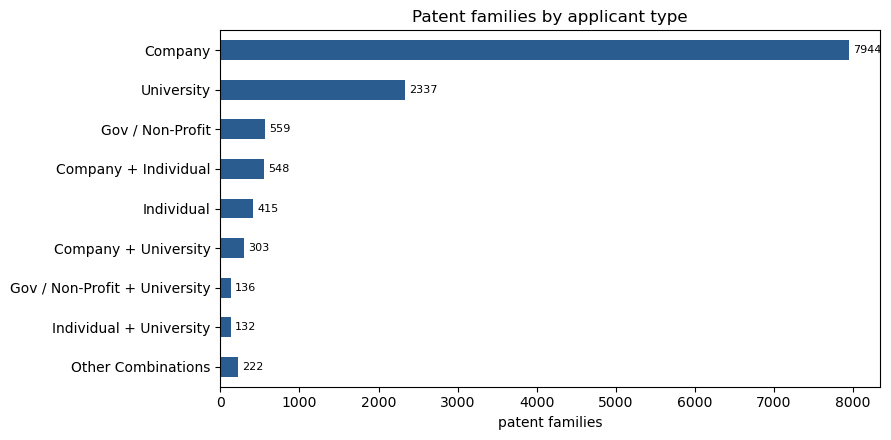

In [10]:
def assign_entity_sector(df):
    "Add `entity_sector`: the most frequent sector of each harmonized entity."
    named = df.dropna(subset=["harmonized_name_final"])
    sector = named.groupby("harmonized_name_final")["psn_sector_imputed"].agg(lambda s: s.mode().iat[0])
    return df.assign(entity_sector=df["harmonized_name_final"].map(sector))


def count_entities_by_type(df):
    "Unique harmonized entities per sector."
    entities = df.dropna(subset=["entity_sector"]).drop_duplicates("harmonized_name_final")
    counts = entities["entity_sector"].value_counts()
    return pd.concat([counts, pd.Series({"TOTAL": counts.sum()})]).to_frame("unique entities")


def families_by_applicant_mix(df, top_n=8):
    "Families per combination of applicant types; rare combinations are grouped."
    mix = (df.groupby("docdb_family_id")["psn_sector_imputed"]
             .agg(lambda s: " + ".join(sorted(s.dropna().unique())))
             .value_counts())
    rest = pd.Series({"Other combinations": mix.iloc[top_n:].sum()})
    return pd.concat([mix.head(top_n), rest]) if len(mix) > top_n else mix


def plot_applicant_mix(mix):
    labels = mix.index.str.title().str.replace("Gov Non-Profit", "Gov / Non-Profit")
    ax = pd.Series(mix.values, index=labels).iloc[::-1].plot.barh(color="#2b5c8f", figsize=(9, 4.5))
    ax.bar_label(ax.containers[0], padding=3, fontsize=8)
    ax.set(title="Patent families by applicant type", xlabel="patent families", ylabel="")
    plt.tight_layout()
    plt.show()

def mix_table(mix):
    "Families per applicant mix, with share of all families and a total row."
    table = mix.to_frame("families")
    table["share (%)"] = (table["families"] / table["families"].sum() * 100).round(1)
    table.loc["TOTAL FAMILIES"] = [table["families"].sum(), 100.0]
    return table.astype({"families": int})


df = assign_entity_sector(df)
display(count_entities_by_type(df))

mix = families_by_applicant_mix(df)
display(mix_table(mix))
plot_applicant_mix(mix)

## 2. Scope of the market analysis

From here on: **companies only**, **families up to `YEAR_MAX`**=2022.

- *Companies only:* concentration and consolidation describe competition between firms. Universities and public bodies follow other incentives.
- *Year cut-off:* applications are published about 18 months after filing, so the latest years are incomplete and would look like a slowdown.



In [ ]:
def build_firm_links(df, sector):
    "One row per (firm, family) for the chosen sector, all years."
    return (df[df["entity_sector"].eq(sector)]
            [["harmonized_name_final", "docdb_family_id", "family_year"]]
            .drop_duplicates(["harmonized_name_final", "docdb_family_id"])
            .set_axis(["firm", "family", "year"], axis=1))


links_all = build_firm_links(df, SECTOR)
firms = links_all[links_all["year"] <= YEAR_MAX]
print(f"{firms['firm'].nunique():,} firms | {firms['family'].nunique():,} families | "
      f"{firms['year'].min()}-{YEAR_MAX}")

## 3. Concentration

Each firm's size is its number of distinct families. Co-owned families count once for each owner, so *families (sum)* is larger than the number of unique families.

| measure | reads as |
|---|---|
| CR4 / CR8 | share of families held by the 4 / 8 largest firms |
| HHI | sum of squared shares (0 = dispersed, 1 = monopoly); **1/HHI** = number of equal-sized firms giving the same HHI |
| CV | spread of firm sizes relative to the mean |
| Gini | inequality of sizes (0 = all equal, 1 = one firm holds everything) |
| Lotka slope | slope of log(firms with *n* families) on log(*n*); steeper = more one-off filers. Descriptive only |

,firms,families (sum),CR4 (%),CR8 (%),HHI,1/HHI,CV,Gini,Lotka slope
"Companies, up to 2022",1035,7823,22.459,32.302,0.022,45.292,4.677,0.788,-0.888


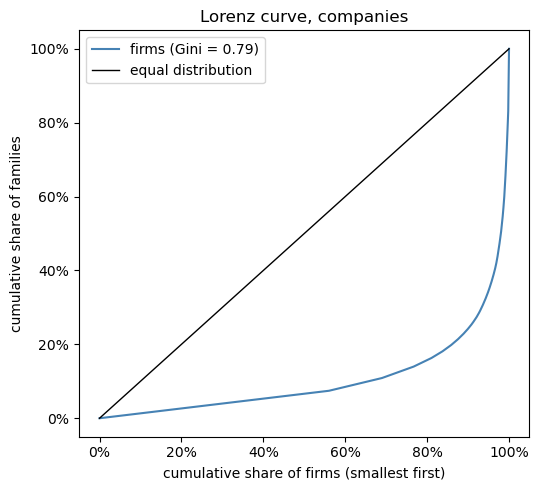

In [6]:
def families_per_firm(links):
    return links.groupby("firm")["family"].nunique().to_numpy()


def gini(sizes):
    sizes = np.sort(sizes)
    n = len(sizes)
    return (2 * np.arange(1, n + 1) - n - 1) @ sizes / (n * sizes.sum())


def lotka_slope(sizes):
    freq = pd.Series(sizes).value_counts()  # n families -> number of firms
    if len(freq) < 3:
        return np.nan
    return stats.linregress(np.log(freq.index), np.log(freq.values)).slope


def concentration_measures(sizes):
    shares = np.sort(sizes)[::-1] / sizes.sum()
    hhi = (shares ** 2).sum()
    return {
        "firms": len(sizes),
        "families (sum)": int(sizes.sum()),
        "CR4 (%)": shares[:4].sum() * 100,
        "CR8 (%)": shares[:8].sum() * 100,
        "HHI": hhi,
        "1/HHI": 1 / hhi,
        "CV": sizes.std(ddof=1) / sizes.mean(),
        "Gini": gini(sizes),
        "Lotka slope": lotka_slope(sizes),
    }


def plot_lorenz(sizes):
    sizes = np.sort(sizes)
    cum_firms = np.arange(len(sizes) + 1) / len(sizes)
    cum_families = np.r_[0, sizes.cumsum() / sizes.sum()]
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot(cum_firms, cum_families, color="steelblue", label=f"firms (Gini = {gini(sizes):.2f})")
    ax.plot([0, 1], [0, 1], color="black", lw=1, label="equal distribution")
    ax.set(title="Lorenz curve, companies", xlabel="cumulative share of firms (smallest first)",
           ylabel="cumulative share of families")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend()
    plt.tight_layout()
    plt.show()


sizes = families_per_firm(firms)
display(pd.DataFrame([concentration_measures(sizes)], index=[f"Companies, up to {YEAR_MAX}"]).round(3))
plot_lorenz(sizes)

## 4. Consolidation

A single concentration figure cannot show **direction**. Here the same measures are computed per period:
if CR4 and HHI rise, the field is consolidating around a few firms; if they fall, new firms are taking share.

Gini partly reflects how many firms there are (more small firms raise it), so CR4 and HHI are the better guide over time.

,firms,CR4 (%),CR8 (%),HHI,1/HHI,Gini
up to 2014,154.0,35.840,51.378,0.049,20.352,0.704
2015-2018,282.0,32.849,47.384,0.039,25.795,0.714
2019-2022,801.0,25.403,33.953,0.026,39.021,0.765


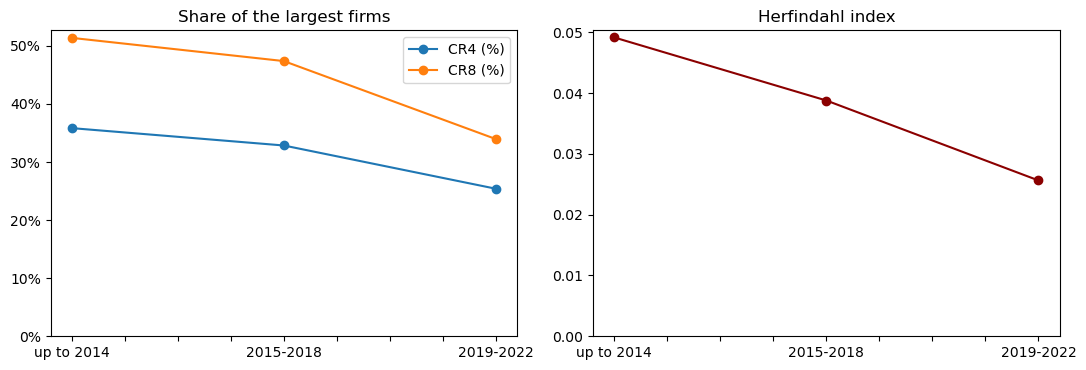

In [7]:
def concentration_by_period(links):
    period = pd.cut(links["year"], bins=PERIOD_BINS, labels=PERIOD_LABELS)
    rows = {p: concentration_measures(families_per_firm(g)) for p, g in links.groupby(period, observed=True)}
    return pd.DataFrame(rows).T[["firms", "CR4 (%)", "CR8 (%)", "HHI", "1/HHI", "Gini"]]


def plot_concentration_trend(table):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    table[["CR4 (%)", "CR8 (%)"]].plot(ax=axes[0], marker="o", title="Share of the largest firms")
    table["HHI"].plot(ax=axes[1], marker="o", color="darkred", title="Herfindahl index")
    axes[0].yaxis.set_major_formatter(PercentFormatter(100))
    for ax in axes:
        ax.set(xlabel="", ylim=(0, None))
    plt.tight_layout()
    plt.show()


by_period = concentration_by_period(firms)
display(by_period.round(3))
plot_concentration_trend(by_period)

### Largest firms
**Incumbent** = at least `MIN_FAMILIES` families before `SPLIT_YEAR`; everyone else is an **entrant**. The threshold avoids labelling as incumbent a firm with a single early, isolated filing.
*Share* is computed over all unique company families up to `YEAR_MAX`.

In [8]:
def top_firms(links, n=20):
    "Largest firms with first filing year and incumbent/entrant status."
    early = links[links["year"] < SPLIT_YEAR].groupby("firm")["family"].nunique()
    by_firm = links.groupby("firm")
    table = pd.DataFrame({"families": by_firm["family"].nunique(), "first year": by_firm["year"].min()})
    table["share (%)"] = table["families"] / links["family"].nunique() * 100
    table["status"] = np.where(table.index.isin(early[early >= MIN_FAMILIES].index), "incumbent", "entrant")
    return table.nlargest(n, "families").round(1)


top_firms(firms)

,families,first year,share (%),status
firm,,,,
IBM INTERNATIONAL BUSINESS MACHINES,667,1994,9.7,incumbent
ORIGIN QUANTUM COMPUTING TECH HEFEI,651,2017,9.5,entrant
MICROSOFT TECH LICENSING,224,2004,3.3,incumbent
BEIJING BAIDU NETCOM SCIENCE TECH,215,2019,3.1,entrant
D WAVE SYSTEMS,213,1999,3.1,incumbent
国际商业机器,198,2011,2.9,incumbent
GOOGLE,187,2013,2.7,incumbent
RUBAN QUANTUM TECH,172,2018,2.5,entrant
INTEL,163,2000,2.4,entrant


## 5. Entry and exit

For each year, among companies:
- **active firms**: firms with at least one family that year; **new firms**: firms filing their *first* family that year.
- **entrants' share of families**: % of that year's families with at least one first-time firm, i.e. how much activity comes from newcomers.
- **exit rate**: % of active firms that **never file again** afterwards. This is an *apparent* exit: a firm may simply pause.
  It is left blank for the last `EXIT_WINDOW` observed years, because we cannot yet tell whether those firms will file again.

Reading: many entrants with low exit means the field is widening; rising exit together with rising concentration means consolidation.

,active_firms,new_firms,last_filing,exit rate (%),entrants' share of families (%)
year,,,,,
2005,19,8,6,31.6,24.3
2006,21,9,3,14.3,15.8
2007,32,14,6,18.8,28.8
2008,20,4,4,20.0,15.2
2009,17,6,3,17.6,15.4
2010,18,7,7,38.9,22.6
2011,26,12,6,23.1,26.1
2012,20,5,6,30.0,13.5
2013,25,11,6,24.0,25.0


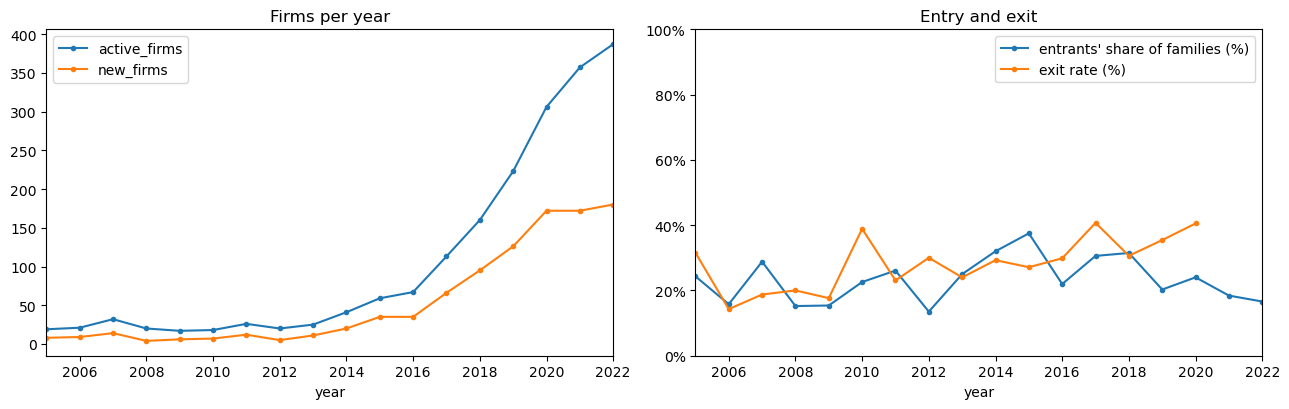

In [9]:
def entry_exit(links_all):
    "Yearly active, new and leaving firms, using the full history to detect exits."
    first = links_all.groupby("firm")["year"].min()
    last = links_all.groupby("firm")["year"].max()

    active = links_all[["firm", "year"]].drop_duplicates()
    active = active.assign(new=active["year"].eq(active["firm"].map(first)),
                           leaving=active["year"].eq(active["firm"].map(last)))
    table = active.groupby("year").agg(active_firms=("firm", "size"),
                                       new_firms=("new", "sum"),
                                       last_filing=("leaving", "sum"))

    table["exit rate (%)"] = table["last_filing"] / table["active_firms"] * 100
    too_recent = table.index > links_all["year"].max() - EXIT_WINDOW
    table.loc[too_recent, "exit rate (%)"] = np.nan

    family_has_newcomer = (links_all.assign(new=links_all["year"].eq(links_all["firm"].map(first)))
                           .groupby(["year", "family"])["new"].any())
    table["entrants' share of families (%)"] = family_has_newcomer.groupby("year").mean() * 100
    return table.loc[PLOT_FROM:YEAR_MAX]


def plot_entry_exit(table):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    table[["active_firms", "new_firms"]].plot(ax=axes[0], marker="o", ms=3, title="Firms per year")
    table[["entrants' share of families (%)", "exit rate (%)"]].plot(
        ax=axes[1], marker="o", ms=3, ylim=(0, 100), title="Entry and exit")
    axes[1].yaxis.set_major_formatter(PercentFormatter(100))
    for ax in axes:
        ax.set(xlabel="year", xlim=(PLOT_FROM, YEAR_MAX))
    plt.tight_layout()
    plt.show()


entry_exit_table = entry_exit(links_all)
display(entry_exit_table.round(1))
plot_entry_exit(entry_exit_table)

## Pest

## Political
Governments see quantum computing as a strategic technology and fund it directly. In 2018 the US passed the National Quantum Initiative, with near-unanimous support, pledging core government funding of $1.3 billion over five years (US National Quantum Initiative website (quantum.gov)) . In the same year the EU launched its Quantum Technologies Flagship (European Commission, Quantum Technologies Flagship (digital-strategy.ec.europa.eu)). 
Link to our data: Do US and European filings grow faster after 2018? Does the share of universities and public research bodies grow in the same years?


China has supported quantum technology for a long time. Quantum communication and computing were referenced in the 13th Five-Year Plan in 2016, and the 14th Five-Year Plan (2021) named quantum computing again as a frontier technology. Hefei, home of the University of Science and Technology of China (USTC), became the main national hub. (CSIS, Understanding China's Quest for Quantum Advancement.) Link to our data: This is the clearest factor in our data. Origin Quantum (Hefei) is second in the top 15 and entered only in 2017; USTC is the only university in the top 15; Baidu is also a new entrant. We can show China's share of families by year.

US–China technology rivalry --> Quantum is treated as a national security topic. The US Bureau of Industry and Security started a review of controls on emerging technologies, including quantum, already in 2018. This pushes each country to build its own supply chain.
https://www.rusi.org/explore-our-research/publications/commentary/export-controls-accelerate-chinas-quantum-supply-chain

Outlook (after 2023): The US introduced new export controls on quantum computing in September 2024; the EU adopted a Quantum Europe Strategy in 2025; China's 15th Five-Year Plan (2026–2030) identifies quantum technology as the first among seven "future industries". Political support and rivalry are both getting stronger

## Economic

Private money started to flow into quantum start-ups. According to McKinsey, private investment rose from about 0.2 billion in 2019 to roughly $2.1 billion in 2021. Some start-ups, like IonQ, Rigetti and D-Wave, also went public. https://www.mckinsey.com/featured-insights/charts/quantum-investment-surge

Building a quantum computer is very expensive. The OECD notes that due to their complexity and cost, access to quantum computers may be dominated by large technology companies. Concentration by type. Companies are much more concentrated (CR4 27%, Gini 0.82) than universities (CR4 14%), and the top companies (IBM, Google, Microsoft, Fujitsu, Intel) are all incumbents. https://thequantuminsider.com/2025/02/08/governments-face-key-challenges-in-quantum-technology-policy-oecd-report-finds/

Big players buy or merge with smaller ones. IBM bought Red Hat (2019), and Honeywell Quantum Solutions merged with Cambridge Quantum to form Quantinuum (2021).These deals are inside our data. They show that concentration can grow through acquisitions, not only through new patents. This links to the "Consolidate" section.

Outlook (after 2023): Investment exploded. Investment in quantum technology start-ups reached $12.6 billion in 2025, 6.3 times higher than in 2024, and it is concentrated in a few large start-ups https://www.mckinsey.com/featured-insights/charts/quantum-investment-surge

## Social

There are not enough people with quantum skills. The OECD finds that the most pressing weakness lies in quantum algorithms and their use cases, and that it is hard to find people who can connect quantum and classical computing.Weight of universities in the field, and families co-owned by companies and universities (first table). Many co-owned patents mean that firms look for knowledge outside. https://www.oecd.org/en/publications/building-business-readiness-for-quantum-computing_ee847e5f-en/full-report/component-4.html


Quantum start-ups come out of research. An OECD–EPO study finds that more than half of quantum start-up founders hold a PhD, compared with roughly ten percent among founders more broadly.Universities and public research bodies act as a "nursery" for the field: many entrants are spin-offs.

People and governments worry that a future quantum computer could break today's encryption. For this reason NIST started work on post-quantum cryptography back in 2016.https://www.cliffordchance.com/insights/resources/blogs/talking-tech/en/articles/2025/03/quantum-state-of-play.html

## Technological

In 2019 Google's Sycamore chip performed a task that it claimed was beyond classical supercomputers. This made the field visible and attracted money and new players.Google Quantum AI, Nature (2019).

There is no single winning technology: superconducting qubits (IBM, Google, Origin Quantum), trapped ions (IonQ, Quantinuum), quantum annealing (D-Wave), neutral atoms, photonics. Because no design has won yet, new firms can still enter.The top 15 already mixes approaches (D-Wave: annealing; IonQ: ions; IBM: superconducting). 

Qubits make many errors. Error correction is the key problem to solve before quantum computers become useful, and a lot of research focuses on it.

Since IBM put a quantum computer on the cloud in 2016, anyone can test algorithms without owning hardware. This lowers entry barriers for software firms.Software and IT firms among the entrants (Red Hat, Baidu) and the share of software/algorithm families compared with hardware.
Outlook (after 2023): In December 2024 Google reported with the Willow chip that the more qubits it uses, the more it reduces errors, a first real step on error correction. In August 2024 NIST released the first post-quantum cryptography standards.